# 04a - kNN de raiz em NumPy

Bloco 2 do plano da Parte 2. O código está em `src/lending/knn.py` (`NeighborSearch`, `KNNRegressor`, `KNNClassifier`) e os testes em `tests/test_knn.py`.

Este notebook explica a implementação e verifica-a. A grelha completa (k × pesos, em todos os folds) corre nos notebooks da regressão (04b) e da classificação (04c), com o runner, e é daí que saem os números do relatório.

| Requisito do enunciado | Onde |
|---|---|
| *"Implement the k-nearest neighbors (kNN) algorithm from scratch in Python, using NumPy arrays and a suitable data structure"* | `knn.py`; secção 1 |
| *"Do not substitute a library kNN estimator"* | `knn.py` só usa NumPy. O scikit-learn aparece aqui **apenas** como referência na secção 2 e no *benchmark* da secção 3 |
| *"Explain and document your implementation"* | Secção 1, `docs/04_modelos/knn.md` e as *docstrings* |
| *"Apply your kNN implementation to regression and classification, evaluate it, and discuss the results"* | Secções 5 e 6 (último fold); grelha completa em 04b e 04c |

**Antes de correr:** `01_preprocessamento.ipynb` (gera os pickles).

In [1]:
# Setup: imports e caminhos do projeto
import sys
import time
from pathlib import Path

# Importar o pacote do projeto.
try:
    import lending
except ModuleNotFoundError:
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / "src" / "lending").is_dir():
            sys.path.insert(0, str(parent / "src"))
            break
    import lending

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, roc_auc_score

from lending import config
from lending.baselines import GradeRateBaseline, TermMedianBaseline
from lending.evaluation import positive_proba
from lending.experiment import ColumnDropper, CrossValidationRunner, default_preprocessor
from lending.knn import NEIGHBOR_CACHE, KNNClassifier, KNNRegressor, NeighborSearch
from lending.model_catalog import COLLINEAR_DROP, KNN_K, KNN_REGRESSION_SAMPLE, KNN_WEIGHTS
from lending.plot_style import apply_style
from lending.storage import PickleStore

apply_style()
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Como funciona

**Algoritmo (T04, p. 34–38).** No treino, o kNN só guarda os dados. Na previsão, para cada pedido:

1. calcula a distância euclidiana a **todos** os pontos de treino;
2. escolhe os k mais próximos;
3. devolve a média do alvo dos vizinhos (regressão) ou a proporção de cada classe entre eles (classificação). Com `weights="distance"`, cada vizinho pesa 1/d.

**Estrutura de dados (`NeighborSearch`).** Fazer isto com ciclos em Python seria impraticável: são 50 000 × 60 000 distâncias por fold na regressão. A implementação usa:

- a **matriz de treino** em `float32`, contígua em memória, com a norma ao quadrado de cada linha calculada uma vez no `fit`;
- as **distâncias por blocos** de pedidos, com a identidade

$$\lVert q - x \rVert^2 = \lVert q \rVert^2 + \lVert x \rVert^2 - 2\, q \cdot x$$

  em que o termo $q \cdot x$ de um bloco inteiro é **um único produto de matrizes** (BLAS). A memória fica limitada ao bloco: com 256 pedidos e 50 000 pontos de treino, cerca de 150 MB;
- a **seleção parcial** com `np.argpartition`, que encontra os k menores sem ordenar a linha toda (custo linear); só esses k são ordenados;
- a **distância exata** dos k escolhidos, $\lVert q - x \rVert$, recalculada diretamente. Em `float32`, a fórmula acima perde precisão para pontos muito próximos, e isso pesaria nos pesos 1/d.

| | Custo | Memória |
|---|---|---|
| `fit` | normas: n × p | a matriz de treino (n × p) |
| `predict` | m × n × p (produto de matrizes) + m × n (seleção parcial) | um bloco: 256 × n |

**Vários k de uma vez.** No catálogo, todas as configurações pesquisam os 101 vizinhos (`search_k=101`) e cada uma usa os primeiros k. A última pesquisa fica guardada numa *cache*, identificada pelo conteúdo do treino e dos pedidos. Na grelha, as 10 configurações de um fold (5 valores de k × 2 pesos) partilham as distâncias, que são calculadas **uma só vez por fold**, como previsto na secção 3 do relatório.

## 2. Está correto?

Compara-se com o kNN do scikit-learn (força bruta) em dados aleatórios. O scikit-learn é usado **só como referência**; o modelo do projeto é o nosso.

In [2]:
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor   # só referência

rng = np.random.default_rng(config.RANDOM_SEED)
X_demo, Q_demo = rng.normal(size=(5_000, 30)), rng.normal(size=(1_000, 30))
y_demo = X_demo[:, 0] - X_demo[:, 1] ** 2 + rng.normal(0, 0.5, len(X_demo))
labels_demo = np.where(X_demo[:, 0] + X_demo[:, 2] > 1.2, "Default", "Good standing")

rows = []
for weights in KNN_WEIGHTS:
    for k in (1, 15, 101):
        ours = KNNRegressor(n_neighbors=k, weights=weights).fit(X_demo, y_demo).predict(Q_demo)
        ref = KNeighborsRegressor(n_neighbors=k, weights=weights, algorithm="brute").fit(X_demo, y_demo).predict(Q_demo)
        p_ours = KNNClassifier(n_neighbors=k, weights=weights).fit(X_demo, labels_demo).predict_proba(Q_demo)
        p_ref = KNeighborsClassifier(n_neighbors=k, weights=weights, algorithm="brute").fit(X_demo, labels_demo).predict_proba(Q_demo)
        rows.append({"pesos": weights, "k": k, "regressão: diferença máxima": np.abs(ours - ref).max(),
                     "classificação: diferença máxima": np.abs(p_ours - p_ref).max()})
pd.DataFrame(rows)

,pesos,k,regressão: diferença máxima,classificação: diferença máxima
0,uniform,1,0.000000e+00,0.000000e+00
1,uniform,15,0.000000e+00,0.000000e+00
2,uniform,101,1.110223e-16,0.000000e+00
3,distance,1,1.776357e-15,0.000000e+00
4,distance,15,5.880375e-08,1.724374e-08
5,distance,101,2.330614e-08,5.578074e-09


As diferenças são zero ou da ordem de 10⁻⁷ (arredondamento do `float32`): os resultados coincidem com os do scikit-learn.

## 3. Porquê força bruta e não uma KD-tree

Uma KD-tree divide o espaço em caixas e, numa pesquisa, descarta as caixas que não podem ter vizinhos mais próximos. Em poucas dimensões descarta quase tudo; em muitas dimensões, as distâncias ficam todas parecidas e quase nenhuma caixa pode ser descartada (maldição da dimensionalidade, T05, p. 4).

O *benchmark* mede o tempo de pesquisar os 31 vizinhos de 1 000 pedidos em 20 000 pontos aleatórios, para várias dimensões, com a nossa força bruta e com a `KDTree` do scikit-learn (usada **só** para esta comparação).

,força bruta (s),KD-tree (s)
dimensões,,
2,0.312,0.024
5,0.316,0.084
10,0.292,0.639
20,0.304,1.083
50,0.276,2.609
100,0.380,6.223


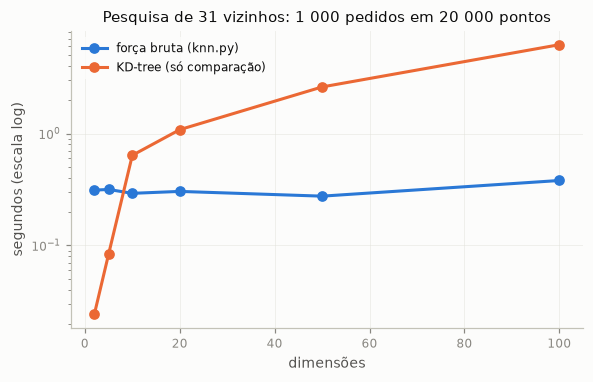

In [3]:
from sklearn.neighbors import KDTree   # só para a comparação

bench = []
for dims in (2, 5, 10, 20, 50, 100):
    Xb = rng.normal(size=(20_000, dims)).astype(np.float32)
    Qb = rng.normal(size=(1_000, dims)).astype(np.float32)
    start = time.perf_counter(); NeighborSearch(Xb).query(Qb, 31); brute = time.perf_counter() - start
    start = time.perf_counter(); KDTree(Xb).query(Qb, k=31); tree = time.perf_counter() - start
    bench.append({"dimensões": dims, "força bruta (s)": brute, "KD-tree (s)": tree})
bench = pd.DataFrame(bench).set_index("dimensões")
display(bench.round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(bench.index, bench["força bruta (s)"], marker="o", label="força bruta (knn.py)")
ax.plot(bench.index, bench["KD-tree (s)"], marker="o", label="KD-tree (só comparação)")
ax.set(xlabel="dimensões", ylabel="segundos (escala log)", yscale="log",
       title="Pesquisa de 31 vizinhos: 1 000 pedidos em 20 000 pontos")
ax.legend()
fig.savefig(config.FIGURES_DIR / "mod_knn_kdtree_benchmark.png")
plt.show()

**Como ler:** em 2 a 5 dimensões a KD-tree ganha; a partir de umas dezenas de dimensões perde a vantagem e fica mais lenta do que a força bruta vetorizada. Os dados do projeto têm cerca de 100 colunas depois do pipeline. Os dados reais têm colunas correlacionadas (a dimensão "efetiva" é menor do que a de dados aleatórios), por isso a secção 5 repete a comparação com os dados reais.

## 4. Dados: último fold de cada tarefa

Usa-se o runner só para ordenar os dados por `issue_d` e obter os folds, e o mesmo pré-processamento do runner (`default_preprocessor`), ajustado no treino do fold. Na regressão, o kNN usa uma amostra de 50 000 empréstimos do treino do fold, com a mesma regra do runner (semente 42, ordem temporal mantida).

In [4]:
def last_fold(task, path, drop=()):
    runner = CrossValidationRunner(task, verbose=False)
    data = runner.prepare(PickleStore.load(path, expected_type=pd.DataFrame))
    *_, (tr, va) = runner.splitter.split(data[runner.task.date_col])
    X_tr, X_va = data[runner.columns].iloc[tr], data[runner.columns].iloc[va]
    y_tr, y_va = data[runner.task.target].iloc[tr], data[runner.task.target].iloc[va]
    prep = default_preprocessor(task).fit(X_tr, y_tr)
    A_tr, A_va = prep.transform(X_tr), prep.transform(X_va)
    if drop:
        dropper = ColumnDropper(drop).fit(A_tr)
        A_tr, A_va = dropper.transform(A_tr), dropper.transform(A_va)
    display(runner.folds(data).tail(1))
    return X_tr, X_va, y_tr, y_va, A_tr, A_va

reg = last_fold("regression", config.REG_DEV_PKL)
X_tr, X_va, y_tr, y_va, A_tr, A_va = reg
if len(A_tr) > KNN_REGRESSION_SAMPLE:   # mesma amostra do runner
    keep = np.sort(np.random.default_rng(config.RANDOM_SEED).choice(len(A_tr), KNN_REGRESSION_SAMPLE, replace=False))
    A_fit, y_fit = A_tr.iloc[keep], y_tr.iloc[keep]
else:
    A_fit, y_fit = A_tr, y_tr
print(f"Regressão: {len(A_fit):,} empréstimos de treino x {A_fit.shape[1]} colunas | {len(A_va):,} de validação")

,treino,validação,linhas treino,linhas validação
fold,,,,
6,2013Q1 a 2014Q3,2014Q4,296180,74098


Regressão: 50,000 empréstimos de treino x 99 colunas | 74,098 de validação


## 5. Regressão: escolha de k e tempos

Como nos slides (T04, p. 38), calcula-se o erro para cada k no treino e na validação. No treino, cada ponto é o seu próprio vizinho, por isso com k = 1 o erro de treino é zero; o k bom é o de menor erro de **validação**. Para o erro de treino usam-se 5 000 pontos do próprio treino.

Graças à *cache*, as distâncias da validação são calculadas uma vez e as outras 9 configurações reutilizam-nas.

In [5]:
NEIGHBOR_CACHE.clear()
train_probe = A_fit.iloc[:: max(1, len(A_fit) // 5_000)][:5_000]
y_probe = y_fit.loc[train_probe.index]
configs = [(weights, k) for weights in KNN_WEIGHTS for k in KNN_K]

def knn(weights, k):
    return KNNRegressor(n_neighbors=k, weights=weights, search_k=max(KNN_K)).fit(A_fit, y_fit)

# 1.º todas as configurações na validação (como no runner), depois todas no treino:
# a cache guarda a última pesquisa, por isso alternar entre os dois obrigaria a recalcular
valid_mae, times = {}, []
for weights, k in configs:
    model = knn(weights, k)
    start = time.perf_counter()
    valid_mae[weights, k] = mean_absolute_error(y_va, model.predict(A_va))
    times.append(time.perf_counter() - start)
cache_log = f"{NEIGHBOR_CACHE.misses} cálculo(s), {NEIGHBOR_CACHE.hits} reutilizações"
train_mae = {(weights, k): mean_absolute_error(y_probe, knn(weights, k).predict(train_probe))
             for weights, k in configs}

curve = pd.DataFrame([{"pesos": w, "k": k, "MAE treino": train_mae[w, k], "MAE validação": valid_mae[w, k]}
                      for w, k in configs])
reference = mean_absolute_error(y_va, TermMedianBaseline().fit(X_tr, y_tr).predict(X_va))
print(f"Previsão da validação: {times[0]:.1f} s na 1.ª configuração e {np.mean(times[1:]):.2f} s em média "
      f"nas outras 9 (cache: {cache_log})")
print(f"MAE da mediana por prazo (referência): {reference:.3f} p.p.")
curve.round(3)

Previsão da validação: 51.5 s na 1.ª configuração e 0.21 s em média nas outras 9 (cache: 1 cálculo(s), 9 reutilizações)
MAE da mediana por prazo (referência): 3.297 p.p.


,pesos,k,MAE treino,MAE validação
0,uniform,5,2.074,2.928
1,uniform,15,2.251,2.805
2,uniform,31,2.325,2.784
3,uniform,51,2.365,2.786
4,uniform,101,2.421,2.800
5,distance,5,0.000,2.926
6,distance,15,0.000,2.803
7,distance,31,0.000,2.782
8,distance,51,0.000,2.784
9,distance,101,0.000,2.797


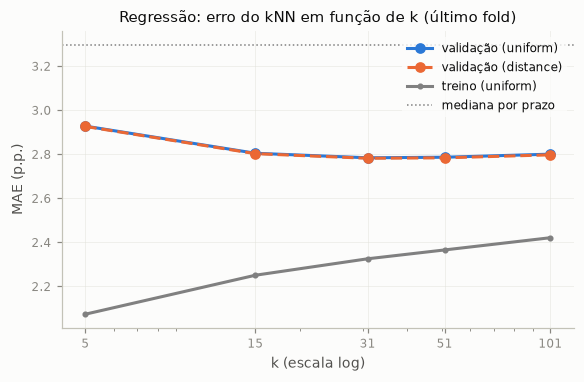

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for weights, style in zip(KNN_WEIGHTS, ("-", "--")):
    part = curve[curve["pesos"] == weights]
    ax.plot(part["k"], part["MAE validação"], marker="o", linestyle=style, label=f"validação ({weights})")
uniform = curve[curve["pesos"] == "uniform"]
ax.plot(uniform["k"], uniform["MAE treino"], marker=".", color="0.5", label="treino (uniform)")
ax.axhline(reference, color="0.5", linewidth=1, linestyle=":", label="mediana por prazo")
ax.set(xscale="log", xticks=KNN_K, xticklabels=KNN_K, xlabel="k (escala log)", ylabel="MAE (p.p.)",
       title="Regressão: erro do kNN em função de k (último fold)")
ax.legend(fontsize=8)
fig.savefig(config.FIGURES_DIR / "mod_knn_k_regressao.png")
plt.show()

**Como ler:** k pequeno = baixo viés e alta variância (erro de treino baixo, validação pior); k grande = previsões mais suaves e mais viés (T04, p. 35). Com pesos pela distância, o erro de treino é sempre 0: cada ponto de treino é vizinho de si próprio a distância 0, e esse peso domina. Por isso o gráfico só mostra a curva de treino dos pesos uniformes. O k escolhido é o mínimo da curva de validação, e no runner é escolhido pela média dos 6 folds, não só por este.

**KD-tree nos dados reais:** a mesma comparação da secção 3, agora com as colunas reais.

In [7]:
from sklearn.neighbors import KDTree   # só para a comparação

queries = A_va.iloc[:2_000].to_numpy(np.float32)
train_matrix = A_fit.to_numpy(np.float32)
start = time.perf_counter(); NeighborSearch(train_matrix).query(queries, 31); brute = time.perf_counter() - start
start = time.perf_counter(); tree = KDTree(train_matrix); build = time.perf_counter() - start
start = time.perf_counter(); tree.query(queries, k=31); query = time.perf_counter() - start
print(f"2 000 pedidos, 31 vizinhos, {train_matrix.shape[0]:,} x {train_matrix.shape[1]}: "
      f"força bruta {brute:.2f} s | KD-tree {build:.2f} s a construir + {query:.2f} s a pesquisar")

2 000 pedidos, 31 vizinhos, 50,000 x 99: força bruta 1.16 s | KD-tree 1.23 s a construir + 24.14 s a pesquisar


## 6. Classificação: escolha de k

Na classificação, o kNN usa o treino inteiro do fold e não usa `dti_with_loan`, que é uma combinação linear de `dti` e `installment_to_income` (secção 3). Mede-se a AUC, que não depende do limiar; o limiar é escolhido pelo runner. A referência é a taxa de *default* do grau.

In [8]:
X_tr_c, X_va_c, y_tr_c, y_va_c, A_tr_c, A_va_c = last_fold("classification", config.CLS_TRAIN_PKL,
                                                            drop=COLLINEAR_DROP)
print(f"Classificação: {len(A_tr_c):,} empréstimos de treino x {A_tr_c.shape[1]} colunas "
      f"(sem {COLLINEAR_DROP}) | {len(A_va_c):,} de validação")

is_default = (y_va_c == "Default").to_numpy()
auc_curve = []
for weights in KNN_WEIGHTS:
    for k in KNN_K:
        model = KNNClassifier(n_neighbors=k, weights=weights, search_k=max(KNN_K)).fit(A_tr_c, y_tr_c)
        auc_curve.append({"pesos": weights, "k": k,
                          "AUC validação": roc_auc_score(is_default, positive_proba(model, A_va_c))})
auc_curve = pd.DataFrame(auc_curve)
grade_auc = roc_auc_score(is_default, positive_proba(GradeRateBaseline().fit(X_tr_c, y_tr_c), X_va_c))
print(f"AUC da taxa do grau (referência): {grade_auc:.3f}")
auc_curve.round(3)

,treino,validação,linhas treino,linhas validação
fold,,,,
3,2007 a 2010,2011,17424,14098


Classificação: 17,424 empréstimos de treino x 115 colunas (sem ('dti_with_loan',)) | 14,098 de validação
AUC da taxa do grau (referência): 0.622


,pesos,k,AUC validação
0,uniform,5,0.564
1,uniform,15,0.602
2,uniform,31,0.624
3,uniform,51,0.639
4,uniform,101,0.649
5,distance,5,0.564
6,distance,15,0.603
7,distance,31,0.625
8,distance,51,0.640
9,distance,101,0.650


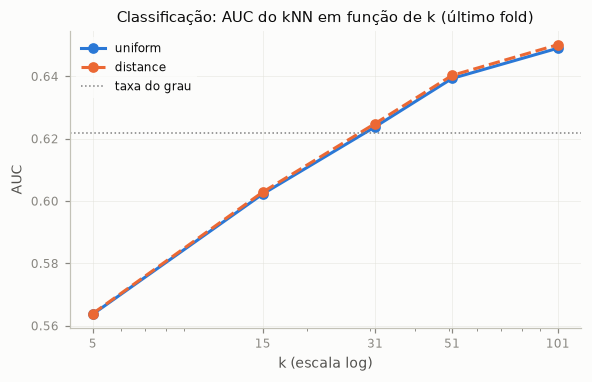

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for weights, style in zip(KNN_WEIGHTS, ("-", "--")):
    part = auc_curve[auc_curve["pesos"] == weights]
    ax.plot(part["k"], part["AUC validação"], marker="o", linestyle=style, label=weights)
ax.axhline(grade_auc, color="0.5", linewidth=1, linestyle=":", label="taxa do grau")
ax.set(xscale="log", xticks=KNN_K, xticklabels=KNN_K, xlabel="k (escala log)", ylabel="AUC",
       title="Classificação: AUC do kNN em função de k (último fold)")
ax.legend()
fig.savefig(config.FIGURES_DIR / "mod_knn_k_classificacao.png")
plt.show()

**Como ler:** com k pequeno, a "probabilidade" só toma poucos valores (com k = 5: 0, 0,2, 0,4...) e a AUC sofre; com k maior, a proporção de *Default* entre os vizinhos fica mais estável. Comparar com a taxa do grau diz se o kNN acrescenta alguma coisa à avaliação da própria LendingClub.

## 7. Resumo e próximos passos

- O kNN está implementado só com NumPy e dá os mesmos resultados do scikit-learn (secção 2).
- A estrutura de dados (matriz em memória, produto de matrizes por blocos, seleção parcial) é a adequada a ~100 colunas; a KD-tree perde a vantagem nesta dimensão (secção 3 e secção 5).
- As 10 configurações de um fold partilham as distâncias, calculadas uma vez.
- **Próximo passo:** a grelha completa corre em 04b e 04c com o runner (`regression_specs()` e `classification_specs()` já incluem o kNN). Os números do relatório saem daí; os deste notebook são de um só fold.